# Run Simulation Notebook

**Workflow note:**
- run this notebook only
- it generates all Step 1 input CSV files (baseline + enhanced)
- then it runs both Step 2 simulations and compares the results

## Section 1: imports and setup

In [29]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scripts import s3_sim as sim


def minutes_to_clock(minute_of_day):
    h = int(minute_of_day) // 60
    m = int(minute_of_day) % 60
    return f"{h:02d}:{m:02d}"


def save_current_figure(output_dir: Path, filename: str, counter: dict, key: str):
    fig = plt.gcf()
    output_dir.mkdir(parents=True, exist_ok=True)
    out_path = output_dir / filename
    fig.savefig(out_path, format="pdf", bbox_inches="tight")
    counter[key] = counter.get(key, 0) + 1
    return out_path


def vehicle_story(row):
    assigned = row["assigned_lot_id"] if pd.notna(row["assigned_lot_id"]) else "None"
    return (
        f"Vehicle {int(row['id'])} ({row['type']}): arrived at {minutes_to_clock(row['arrive_time'])}, "
        f"waited {int(row['waited_time'])} min, service time {int(row['parked_time'])} min, "
        f"final status = {row['status']}, assigned lot = {assigned}."
    )


def prepare_scenario_tables(df_summ_input: pd.DataFrame, df_results_input: pd.DataFrame):
    df_summ = df_summ_input.copy()

    df_veh = df_results_input.rename(
        columns={
            "vehicle_id": "id",
            "vehicle_type": "type",
            "final_status": "status",
            "arrival_time": "arrive_time",
            "assigned_parking_space_id": "assigned_lot_id",
            "waited_time_minutes": "waited_time",
            "parked_time_minutes": "parked_time",
            "max_wait_time_minutes": "max_wait_time",
            "planned_parking_duration_minutes": "park_len",
        }
    ).copy()
    df_veh["status"] = df_veh["status"].str.upper()
    df_veh["served_flag"] = (df_veh["status"] != "FAILED").astype(int)
    df_veh["failed_flag"] = (df_veh["status"] == "FAILED").astype(int)
    df_veh["double_parked_flag"] = df_veh["was_double_parked"].astype(int)
    df_veh["legally_accommodated_flag"] = df_veh["assigned_lot_id"].notna().astype(int)
    df_veh["cruised_flag"] = (df_veh["waited_time"] > 0).astype(int)

    df_summ["clock"] = df_summ["t"].apply(minutes_to_clock)
    df_summ["cumulative_arrivals"] = (
        df_summ["num_arrived"]
        + df_summ["num_parked"]
        + df_summ["num_double_parked"]
        + df_summ["num_departed"]
        + df_summ["num_failed"]
    )
    df_summ["cumulative_departures"] = df_summ["num_departed"] + df_summ["num_failed"]
    df_summ["active_in_system"] = (
        df_summ["num_arrived"]
        + df_summ["num_parked"]
        + df_summ["num_double_parked"]
    )
    df_summ["total_spaces"] = df_summ["num_occupied"] + df_summ["num_empty"]
    df_summ["occupancy_ratio"] = np.where(
        df_summ["total_spaces"] > 0,
        df_summ["num_occupied"] / df_summ["total_spaces"],
        0,
    )

    cars = df_veh[df_veh["type"] == "car"].copy()
    trucks = df_veh[df_veh["type"] == "truck"].copy()

    total_vehicles = len(df_veh)
    total_cars = len(cars)
    total_trucks = len(trucks)

    served_vehicles = int(df_veh["served_flag"].sum())
    failed_vehicles = int(df_veh["failed_flag"].sum())
    legally_accommodated = int(df_veh["legally_accommodated_flag"].sum())
    served_via_double_parking = int(df_veh["double_parked_flag"].sum())

    served_cars = int(cars["served_flag"].sum())
    failed_cars = int(cars["failed_flag"].sum())
    legal_cars = int(cars["legally_accommodated_flag"].sum())

    served_trucks = int(trucks["served_flag"].sum())
    failed_trucks = int(trucks["failed_flag"].sum())
    legal_trucks = int(trucks["legally_accommodated_flag"].sum())
    double_trucks = int(trucks["double_parked_flag"].sum())

    peak_occupied = int(df_summ["num_occupied"].max())
    peak_double_parked = int(df_summ["num_double_parked"].max())
    full_rows = df_summ[df_summ["num_occupied"] == peak_occupied]
    first_full_time = full_rows.iloc[0]["clock"] if len(full_rows) else "N/A"
    peak_waiting = int(df_summ["num_arrived"].max())

    total_car_cruising = int(cars["waited_time"].sum()) if len(cars) else 0
    avg_car_cruising = float(cars["waited_time"].mean()) if len(cars) else 0.0
    max_car_cruising = int(cars["waited_time"].max()) if len(cars) else 0
    cars_cruised = int(cars["cruised_flag"].sum()) if len(cars) else 0
    share_cars_cruised = (cars_cruised / total_cars) if total_cars else 0

    trucks_waited = int((trucks["waited_time"] > 0).sum()) if len(trucks) else 0
    avg_truck_wait = float(trucks["waited_time"].mean()) if len(trucks) else 0.0

    metrics = [
        ("Total vehicles", total_vehicles),
        ("Total cars", total_cars),
        ("Total trucks", total_trucks),
        ("Served vehicles (all)", served_vehicles),
        ("Failed vehicles", failed_vehicles),
        ("Legally accommodated vehicles", legally_accommodated),
        ("Vehicles served via double parking", served_via_double_parking),
        ("Served cars", served_cars),
        ("Failed cars", failed_cars),
        ("Legally accommodated cars", legal_cars),
        ("Served trucks", served_trucks),
        ("Failed trucks", failed_trucks),
        ("Legally accommodated trucks", legal_trucks),
        ("Double-parked trucks", double_trucks),
        ("Peak occupied legal spaces", peak_occupied),
        ("Peak simultaneous double-parked trucks", peak_double_parked),
        ("First full legal occupancy time", first_full_time),
        ("Peak waiting vehicles", peak_waiting),
        ("Total car cruising time (min)", total_car_cruising),
        ("Average car cruising time (min)", round(avg_car_cruising, 2)),
        ("Maximum car cruising time (min)", max_car_cruising),
        ("Cars that cruised", cars_cruised),
        ("Share of cars that cruised", round(share_cars_cruised, 4)),
        ("Trucks that waited", trucks_waited),
        ("Average truck waiting time (min)", round(avg_truck_wait, 2)),
        ("Share of vehicles that failed", round(failed_vehicles / total_vehicles, 4) if total_vehicles else 0),
    ]
    metrics_df = pd.DataFrame(metrics, columns=["Metric", "Value"])

    congestion_mask = df_summ["num_arrived"] > 0
    intervals = []
    in_run = False
    start_t = None
    prev_t = None
    for t, congested in zip(df_summ["t"], congestion_mask):
        if congested and not in_run:
            in_run = True
            start_t = t
        if not congested and in_run:
            end_t = prev_t
            intervals.append((start_t, end_t))
            in_run = False
        prev_t = t
    if in_run:
        intervals.append((start_t, prev_t))

    if intervals:
        congestion_intervals = pd.DataFrame(intervals, columns=["start_t", "end_t"])
        congestion_intervals["start_clock"] = congestion_intervals["start_t"].apply(minutes_to_clock)
        congestion_intervals["end_clock"] = congestion_intervals["end_t"].apply(minutes_to_clock)
        congestion_intervals["duration_min"] = (
            congestion_intervals["end_t"] - congestion_intervals["start_t"] + 1
        )
    else:
        congestion_intervals = pd.DataFrame()

    truck_status_table = (
        trucks.groupby("status", as_index=False)
        .size()
        .rename(columns={"size": "count"})
        .sort_values("status")
    )

    car_example = cars.sort_values(["waited_time", "id"], ascending=[False, True]).head(1)
    truck_example = trucks.sort_values(["waited_time", "id"], ascending=[False, True]).head(1)
    car_story = vehicle_story(car_example.iloc[0]) if len(car_example) else "No car records."
    truck_story = vehicle_story(truck_example.iloc[0]) if len(truck_example) else "No truck records."

    return {
        "df_summ": df_summ,
        "df_veh": df_veh,
        "cars": cars,
        "trucks": trucks,
        "metrics_df": metrics_df,
        "congestion_intervals": congestion_intervals,
        "truck_status_table": truck_status_table,
        "car_story": car_story,
        "truck_story": truck_story,
    }


def plot_scenario_timeseries(data: dict, prefix: str, output_dir: Path, counter: dict, counter_key: str):
    df_summ = data["df_summ"]

    fig, ax = plt.subplots(figsize=(9, 4), dpi=150)
    ax.plot(df_summ["t"], df_summ["cumulative_arrivals"], label="Cumulative arrivals")
    ax.plot(df_summ["t"], df_summ["cumulative_departures"], label="Cumulative departures")
    ax.set_title("Cumulative Arrivals and Departures Over Time")
    ax.set_xlabel("Time (minute of day)")
    ax.set_ylabel("Number of vehicles")
    ax.grid(True, alpha=0.3)
    ax.legend()
    save_current_figure(output_dir, f"{prefix}_plot_01_cumulative_arrivals_departures.pdf", counter, counter_key)
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 4), dpi=150)
    ax.plot(df_summ["t"], df_summ["num_occupied"], label="Occupied spaces")
    ax.plot(df_summ["t"], df_summ["num_empty"], label="Empty spaces")
    ax.set_title("Parking Occupancy Over Time")
    ax.set_xlabel("Time (minute of day)")
    ax.set_ylabel("Number of spaces")
    ax.grid(True, alpha=0.3)
    ax.legend()
    save_current_figure(output_dir, f"{prefix}_plot_02_parking_occupancy.pdf", counter, counter_key)
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 4), dpi=150)
    ax.plot(df_summ["t"], df_summ["num_arrived"], label="Waiting / arrived")
    ax.plot(df_summ["t"], df_summ["num_parked"], label="Legally parked")
    ax.plot(df_summ["t"], df_summ["num_double_parked"], label="Double parked")
    ax.plot(df_summ["t"], df_summ["num_departed"], label="Departed")
    ax.plot(df_summ["t"], df_summ["num_failed"], label="Failed")
    ax.set_title("Vehicle States Over Time")
    ax.set_xlabel("Time (minute of day)")
    ax.set_ylabel("Number of vehicles")
    ax.grid(True, alpha=0.3)
    ax.legend()
    save_current_figure(output_dir, f"{prefix}_plot_03_vehicle_states.pdf", counter, counter_key)
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 4), dpi=150)
    ax.plot(df_summ["t"], df_summ["num_arrived"], label="Waiting vehicles")
    ax.plot(df_summ["t"], df_summ["active_in_system"], label="Active vehicles in system")
    ax.plot(df_summ["t"], df_summ["num_double_parked"], label="Double parked trucks")
    ax.set_title("Congestion and Active Demand Over Time")
    ax.set_xlabel("Time (minute of day)")
    ax.set_ylabel("Number of vehicles")
    ax.grid(True, alpha=0.3)
    ax.legend()
    save_current_figure(output_dir, f"{prefix}_plot_04_congestion_active_demand.pdf", counter, counter_key)
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 4), dpi=150)
    ax.plot(df_summ["t"], df_summ["num_failed"], label="Failed vehicles")
    ax.set_title("Failed Vehicles Over Time")
    ax.set_xlabel("Time (minute of day)")
    ax.set_ylabel("Number of vehicles")
    ax.grid(True, alpha=0.3)
    ax.legend()
    save_current_figure(output_dir, f"{prefix}_plot_05_failed_vehicles.pdf", counter, counter_key)
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 4), dpi=150)
    ax.plot(df_summ["t"], df_summ["occupancy_ratio"], label="Occupancy ratio")
    ax.set_title("Occupancy Ratio Over Time")
    ax.set_xlabel("Time (minute of day)")
    ax.set_ylabel("Occupancy ratio")
    ax.grid(True, alpha=0.3)
    ax.legend()
    save_current_figure(output_dir, f"{prefix}_plot_06_occupancy_ratio.pdf", counter, counter_key)
    plt.show()

## Section 2: define project paths and output folders

In [30]:
ROOT = Path.cwd()
BASELINE_DRIVERS = ROOT / "data" / "drivers.csv"
BASELINE_LOTS = ROOT / "data" / "parking_lots.csv"
ENHANCED_DRIVERS = ROOT / "data" / "drivers_enhanced.csv"
ENHANCED_LOTS = ROOT / "data" / "parking_lots_enhanced.csv"

from pathlib import Path

BASE_RESULTS_DIR = Path("results")
BASELINE_DIR = BASE_RESULTS_DIR / "base_conditions"
ENHANCED_DIR = BASE_RESULTS_DIR / "enhanced"
COMPARISON_DIR = BASE_RESULTS_DIR / "comparison"

for d in [BASELINE_DIR, ENHANCED_DIR, COMPARISON_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# Keep backward-compatible aliases used in existing cells
RESULTS_DIR = BASE_RESULTS_DIR
BASE_PLOTS_DIR = BASELINE_DIR
ENHANCED_PLOTS_DIR = ENHANCED_DIR
COMPARISON_PLOTS_DIR = COMPARISON_DIR

PLOT_SAVE_COUNTS = {
    "base_conditions": 0,
    "enhanced": 0,
    "comparison": 0,
}

print("Running from:", ROOT)
print("Baseline input files:", BASELINE_DRIVERS, BASELINE_LOTS)
print("Enhanced input files:", ENHANCED_DRIVERS, ENHANCED_LOTS)
print("Output folders:", BASELINE_DIR, ENHANCED_DIR, COMPARISON_DIR)

Running from: c:\Users\ABBAS MANSOUR\Desktop\CE2710\CurbParkSIM_python\src
Baseline input files: c:\Users\ABBAS MANSOUR\Desktop\CE2710\CurbParkSIM_python\src\data\drivers.csv c:\Users\ABBAS MANSOUR\Desktop\CE2710\CurbParkSIM_python\src\data\parking_lots.csv
Enhanced input files: c:\Users\ABBAS MANSOUR\Desktop\CE2710\CurbParkSIM_python\src\data\drivers_enhanced.csv c:\Users\ABBAS MANSOUR\Desktop\CE2710\CurbParkSIM_python\src\data\parking_lots_enhanced.csv
Output folders: results\base_conditions results\enhanced results\comparison


In [31]:
from matplotlib.animation import FuncAnimation, PillowWriter


def save_system_animation(ts_df, out_gif_path: Path, title: str):
    t = ts_df["t"].to_numpy()
    occupied = ts_df["num_occupied"].to_numpy()
    waiting = ts_df["num_arrived"].to_numpy()
    double_parked = ts_df["num_double_parked"].to_numpy()

    frame_step = max(1, len(t) // 80)
    frame_idx = list(range(0, len(t), frame_step))
    if frame_idx[-1] != len(t) - 1:
        frame_idx.append(len(t) - 1)

    fig, ax = plt.subplots(figsize=(9, 4), dpi=150)
    line_occ, = ax.plot([], [], linewidth=2.5, label="Occupied spaces")
    line_wait, = ax.plot([], [], linewidth=2.5, label="Waiting vehicles")
    line_dp, = ax.plot([], [], linewidth=2.5, label="Double parked trucks")

    ax.set_title(title)
    ax.set_xlabel("Time (minute of day)")
    ax.set_ylabel("Count")
    ax.grid(True, alpha=0.3)
    ax.legend()
    ax.set_xlim(t.min(), t.max())
    ax.set_ylim(0, max(occupied.max(), waiting.max(), double_parked.max()) + 1)

    def update(frame_number):
        i = frame_idx[frame_number]
        line_occ.set_data(t[: i + 1], occupied[: i + 1])
        line_wait.set_data(t[: i + 1], waiting[: i + 1])
        line_dp.set_data(t[: i + 1], double_parked[: i + 1])
        return line_occ, line_wait, line_dp

    anim = FuncAnimation(fig, update, frames=len(frame_idx), interval=80, blit=True)
    anim.save(out_gif_path, writer=PillowWriter(fps=10))
    plt.tight_layout()
    plt.show()

## Section 3: generate Step 1 inputs (baseline and enhanced)

In [32]:
from scripts import s1_gen_demands
from scripts import s1_gen_lots
from scripts import s1_gen_demands_enhanced
from scripts import s1_gen_lots_enhanced

s1_gen_demands.main([])
s1_gen_lots.main([])
s1_gen_demands_enhanced.main([])
s1_gen_lots_enhanced.main([])

print("Step 1 generation complete:")
print(" - data/drivers.csv")
print(" - data/parking_lots.csv")
print(" - data/drivers_enhanced.csv")
print(" - data/parking_lots_enhanced.csv")

Enhanced demand file written to: C:\Users\ABBAS MANSOUR\Desktop\CE2710\CurbParkSIM_python\src\data\drivers_enhanced.csv
Enhanced parking lots file written to: C:\Users\ABBAS MANSOUR\Desktop\CE2710\CurbParkSIM_python\src\data\parking_lots_enhanced.csv
Step 1 generation complete:
 - data/drivers.csv
 - data/parking_lots.csv
 - data/drivers_enhanced.csv
 - data/parking_lots_enhanced.csv


## Section 4: run baseline simulation

In [33]:
baseline_time_series = sim.run_from_files(
    drivers_path=BASELINE_DRIVERS,
    lots_path=BASELINE_LOTS,
)

baseline_results_source = RESULTS_DIR / "simulation_results.csv"
baseline_summary_source = RESULTS_DIR / "simulation_summary.csv"

baseline_results_path = BASELINE_DIR / "baseline_results.csv"
baseline_summary_path = BASELINE_DIR / "baseline_summary.csv"

pd.read_csv(baseline_results_source).to_csv(baseline_results_path, index=False)
pd.read_csv(baseline_summary_source).to_csv(baseline_summary_path, index=False)
if baseline_results_source.exists():
    baseline_results_source.unlink()
if baseline_summary_source.exists():
    baseline_summary_source.unlink()

print("Baseline simulation complete")
print("Baseline results:", baseline_results_path)
print("Baseline summary:", baseline_summary_path)
display(baseline_time_series.head())

..............................................................Baseline simulation complete
Baseline results: results\base_conditions\baseline_results.csv
Baseline summary: results\base_conditions\baseline_summary.csv


,t,num_future,num_arrived,num_parked,num_double_parked,num_departed,num_failed,num_empty,num_occupied
0,480,215,0,1,0,0,0,37,1
1,481,215,0,1,0,0,0,37,1
2,482,214,0,2,0,0,0,36,2
3,483,214,0,2,0,0,0,36,2
4,484,213,0,3,0,0,0,35,3


## Section 5: run enhanced simulation

In [34]:
enhanced_time_series = sim.run_from_files(
    drivers_path=ENHANCED_DRIVERS,
    lots_path=ENHANCED_LOTS,
)

enhanced_results_source = RESULTS_DIR / "simulation_results_enhanced.csv"
enhanced_summary_source = RESULTS_DIR / "simulation_summary_enhanced.csv"

enhanced_results_path = ENHANCED_DIR / "enhanced_results.csv"
enhanced_summary_path = ENHANCED_DIR / "enhanced_summary.csv"

pd.read_csv(enhanced_results_source).to_csv(enhanced_results_path, index=False)
pd.read_csv(enhanced_summary_source).to_csv(enhanced_summary_path, index=False)
if enhanced_results_source.exists():
    enhanced_results_source.unlink()
if enhanced_summary_source.exists():
    enhanced_summary_source.unlink()

print("Enhanced simulation complete")
print("Enhanced results:", enhanced_results_path)
print("Enhanced summary:", enhanced_summary_path)
display(enhanced_time_series.head())

..........................................................Enhanced simulation complete
Enhanced results: results\enhanced\enhanced_results.csv
Enhanced summary: results\enhanced\enhanced_summary.csv


,t,num_future,num_arrived,num_parked,num_double_parked,num_departed,num_failed,num_empty,num_occupied
0,480,215,0,1,0,0,0,37,1
1,481,215,0,1,0,0,0,37,1
2,482,214,0,2,0,0,0,36,2
3,483,214,0,2,0,0,0,36,2
4,484,213,0,3,0,0,0,35,3


## Section 6: load baseline and enhanced results

In [35]:
baseline_results = pd.read_csv(baseline_results_path)
enhanced_results = pd.read_csv(enhanced_results_path)
baseline_summary = pd.read_csv(baseline_summary_path)
enhanced_summary = pd.read_csv(enhanced_summary_path)

print("Baseline results shape:", baseline_results.shape)
print("Enhanced results shape:", enhanced_results.shape)
display(baseline_summary)
display(enhanced_summary)

Baseline results shape: (216, 11)
Enhanced results shape: (216, 11)


,total_vehicles,parked_vehicles,double_parked_vehicles,failed_vehicles,departed_vehicles,avg_waited_time_minutes
0,216,197,15,4,212,0.731


,total_vehicles,parked_vehicles,double_parked_vehicles,failed_vehicles,departed_vehicles,avg_waited_time_minutes
0,216,216,0,0,216,0.0


## Section 7: baseline analysis and plots

,Metric,Value
0,Total vehicles,216
1,Total cars,200
2,Total trucks,16
3,Served vehicles (all),212
4,Failed vehicles,4
5,Legally accommodated vehicles,197
6,Vehicles served via double parking,15
7,Served cars,196
8,Failed cars,4
9,Legally accommodated cars,196


,t,num_future,num_arrived,num_parked,num_double_parked,num_departed,num_failed,num_empty,num_occupied,clock,cumulative_arrivals,cumulative_departures,active_in_system,total_spaces,occupancy_ratio
0,480,215,0,1,0,0,0,37,1,08:00,1,0,1,38,0.026316
1,481,215,0,1,0,0,0,37,1,08:01,1,0,1,38,0.026316
2,482,214,0,2,0,0,0,36,2,08:02,2,0,2,38,0.052632
3,483,214,0,2,0,0,0,36,2,08:03,2,0,2,38,0.052632
4,484,213,0,3,0,0,0,35,3,08:04,3,0,3,38,0.078947


,id,type,status,arrive_time,departure_time,assigned_lot_id,waited_time,parked_time,max_wait_time,park_len,was_double_parked,served_flag,failed_flag,double_parked_flag,legally_accommodated_flag,cruised_flag
0,0,car,DEPARTED,480,598.0,38.0,0,118,15,118,False,1,0,0,1,0
1,1,car,DEPARTED,482,594.0,37.0,0,112,15,112,False,1,0,0,1,0
2,2,car,DEPARTED,484,581.0,36.0,0,97,15,97,False,1,0,0,1,0
3,3,car,DEPARTED,487,602.0,35.0,0,115,15,115,False,1,0,0,1,0
4,4,car,DEPARTED,491,594.0,34.0,0,103,15,103,False,1,0,0,1,0


Total number of congestion intervals: 7

Longest congestion interval:


,start_t,end_t,start_clock,end_clock,duration_min
0,586,610,09:46,10:10,25


,start_t,end_t,start_clock,end_clock,duration_min
0,586,610,09:46,10:10,25
1,612,614,10:12,10:14,3
2,708,708,11:48,11:48,1
3,712,733,11:52,12:13,22
4,795,796,13:15,13:16,2
5,798,801,13:18,13:21,4
6,804,810,13:24,13:30,7


... (2 outputs left out)

Average truck waiting time: 0.0 min
Maximum truck waiting time: 0 min
Served trucks: 16
Failed trucks: 0
Legally accommodated trucks: 1
Double-parked trucks: 15


,id,status,was_double_parked,double_parked_flag,assigned_lot_id
13,13,DEPARTED,False,0,24.0
31,31,DEPARTED,True,1,NaN
32,32,DEPARTED,True,1,NaN
38,38,DEPARTED,True,1,NaN
51,51,DEPARTED,True,1,NaN
86,86,DEPARTED,True,1,NaN
90,90,DEPARTED,True,1,NaN
94,94,DEPARTED,True,1,NaN
103,103,DEPARTED,True,1,NaN
118,118,DEPARTED,True,1,NaN


,id,status,waited_time,max_wait_time
47,47,FAILED,16,15
54,54,FAILED,16,15
107,107,FAILED,16,15
105,105,FAILED,16,15
109,109,DEPARTED,10,15
108,108,DEPARTED,8,15
58,58,DEPARTED,7,15
48,48,DEPARTED,7,15
145,145,DEPARTED,7,15
146,146,DEPARTED,7,15


Representative car:
Vehicle 47 (car): arrived at 09:46, waited 16 min, service time 0 min, final status = FAILED, assigned lot = None.

Representative truck:
Vehicle 13 (truck): arrived at 08:37, waited 0 min, service time 30 min, final status = DEPARTED, assigned lot = 24.0.


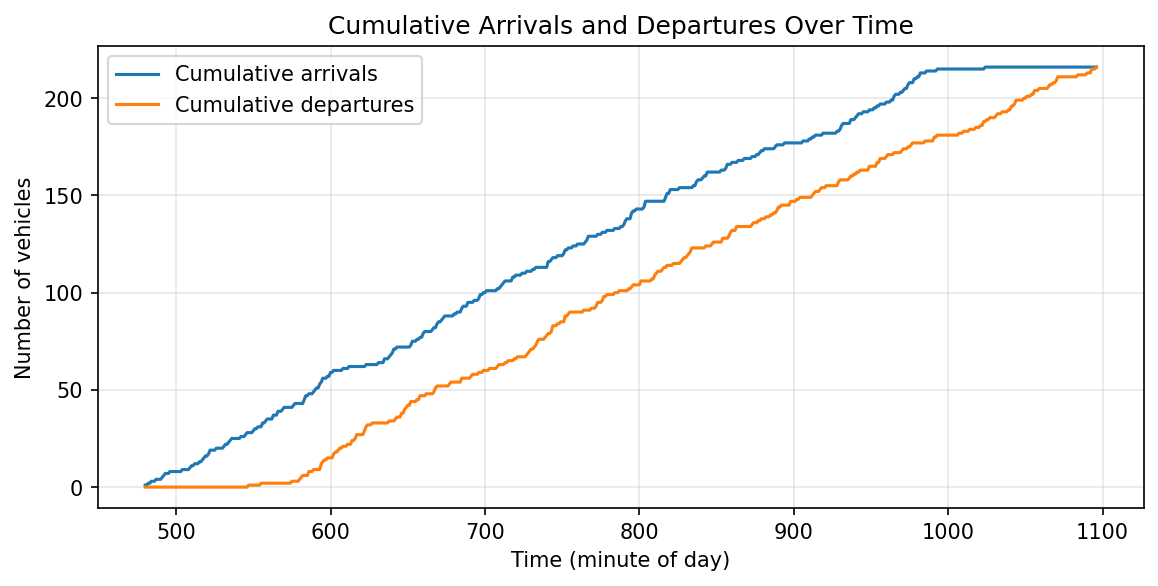

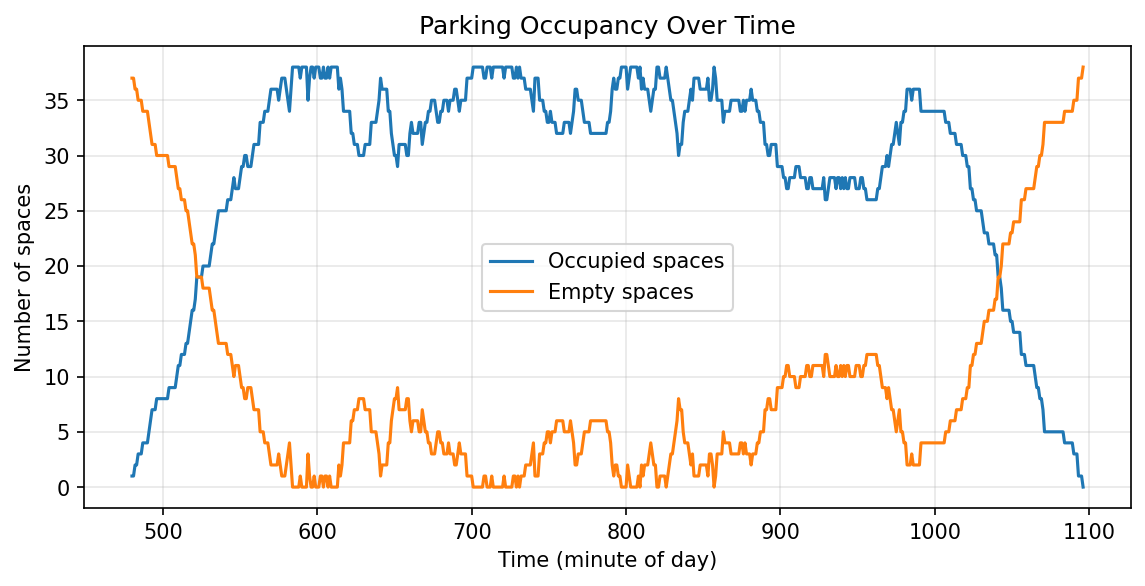

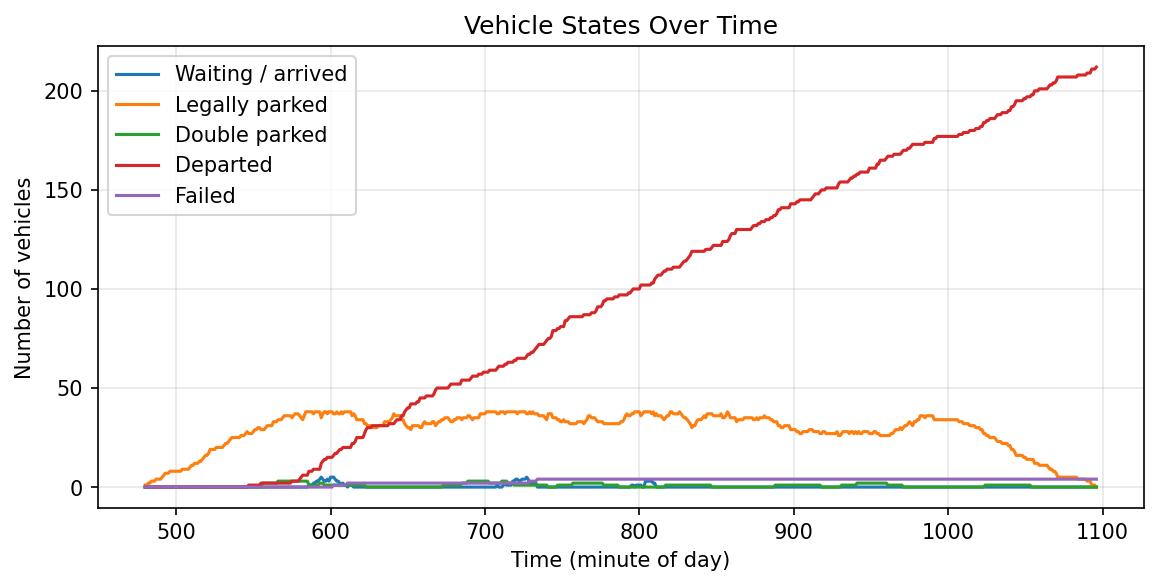

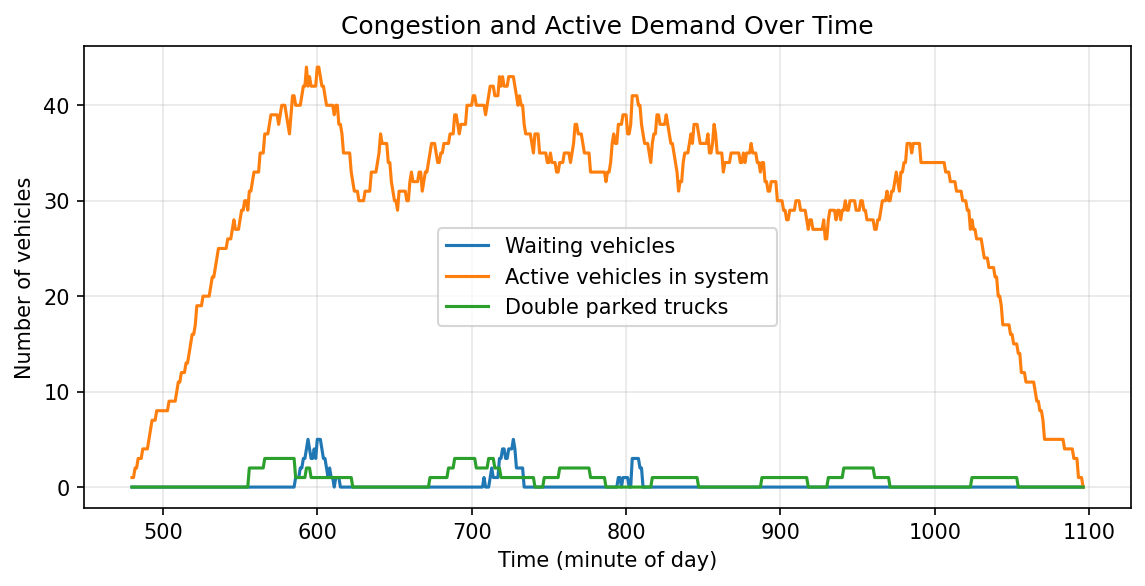

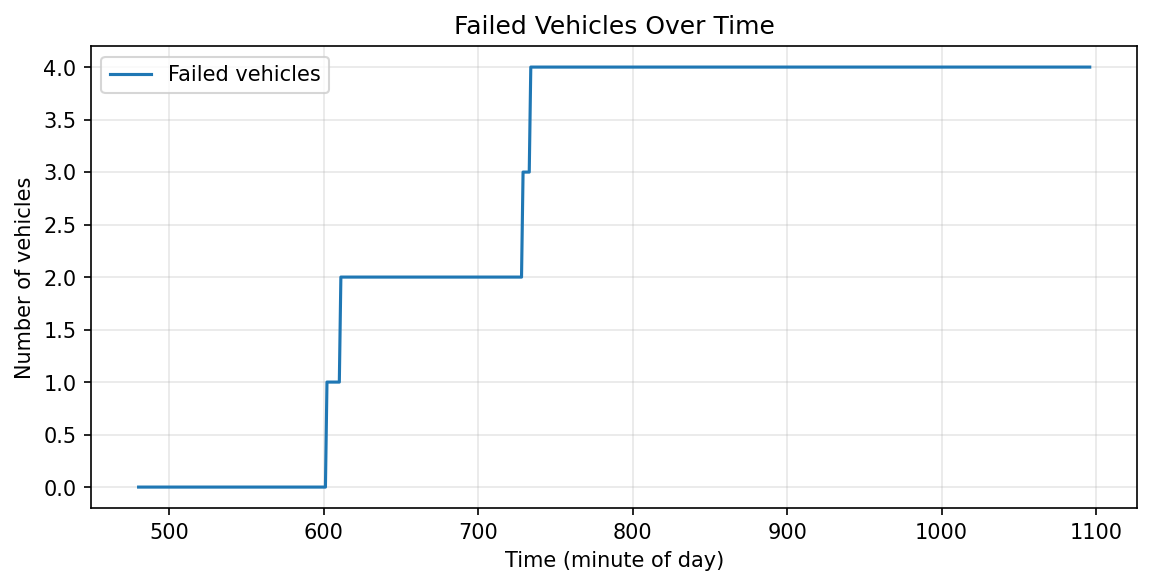

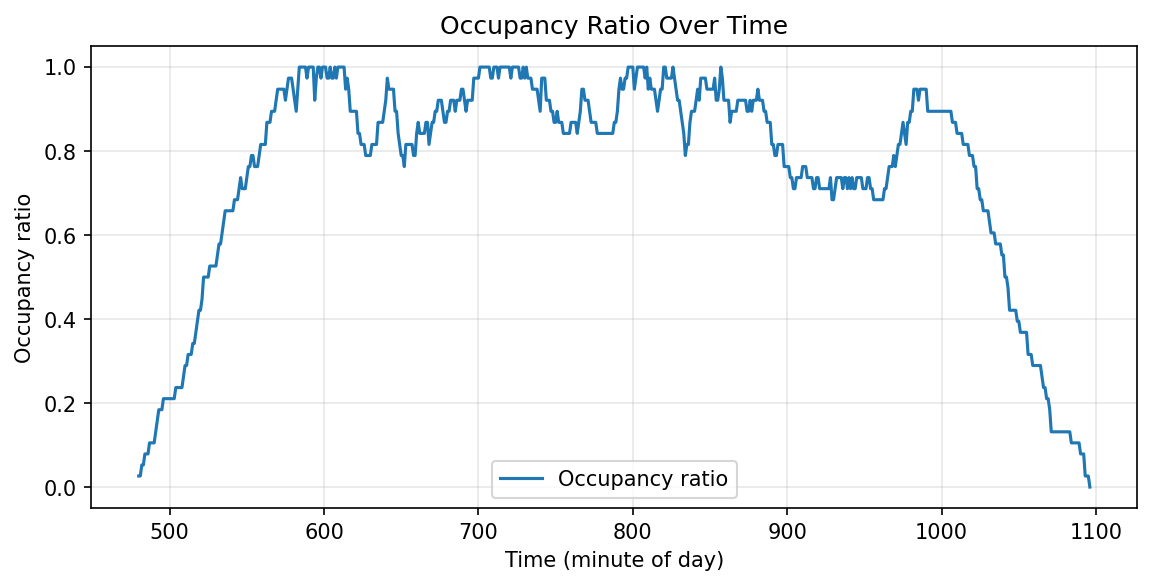

In [36]:
baseline_data = prepare_scenario_tables(baseline_time_series, baseline_results)

display(baseline_data["metrics_df"])
display(baseline_data["df_summ"].head())
display(baseline_data["df_veh"].head())

print("Total number of congestion intervals:", len(baseline_data["congestion_intervals"]))
if len(baseline_data["congestion_intervals"]):
    print("\nLongest congestion interval:")
    display(baseline_data["congestion_intervals"].sort_values("duration_min", ascending=False).head(1))
    display(baseline_data["congestion_intervals"])

print("Truck outcomes by status:")
display(baseline_data["truck_status_table"])
print(
    "Average truck waiting time:",
    round(float(baseline_data["trucks"]["waited_time"].mean()) if len(baseline_data["trucks"]) else 0.0, 2),
    "min",
)
print(
    "Maximum truck waiting time:",
    int(baseline_data["trucks"]["waited_time"].max()) if len(baseline_data["trucks"]) else 0,
    "min",
)

served_trucks = int((baseline_data["trucks"]["status"] != "FAILED").sum())
failed_trucks = int((baseline_data["trucks"]["status"] == "FAILED").sum())
legal_trucks = int(baseline_data["trucks"]["assigned_lot_id"].notna().sum())
double_trucks = int(baseline_data["trucks"]["was_double_parked"].sum())

print("Served trucks:", served_trucks)
print("Failed trucks:", failed_trucks)
print("Legally accommodated trucks:", legal_trucks)
print("Double-parked trucks:", double_trucks)

display(
    baseline_data["trucks"][
        ["id", "status", "was_double_parked", "double_parked_flag", "assigned_lot_id"]
    ].head(20)
)
display(
    baseline_data["cars"][["id", "status", "waited_time", "max_wait_time"]]
    .sort_values("waited_time", ascending=False)
    .head(20)
)

print("Representative car:")
print(baseline_data["car_story"])
print("\nRepresentative truck:")
print(baseline_data["truck_story"])

plot_scenario_timeseries(
    baseline_data,
    prefix="baseline",
    output_dir=BASE_PLOTS_DIR,
    counter=PLOT_SAVE_COUNTS,
    counter_key="base_conditions",
)

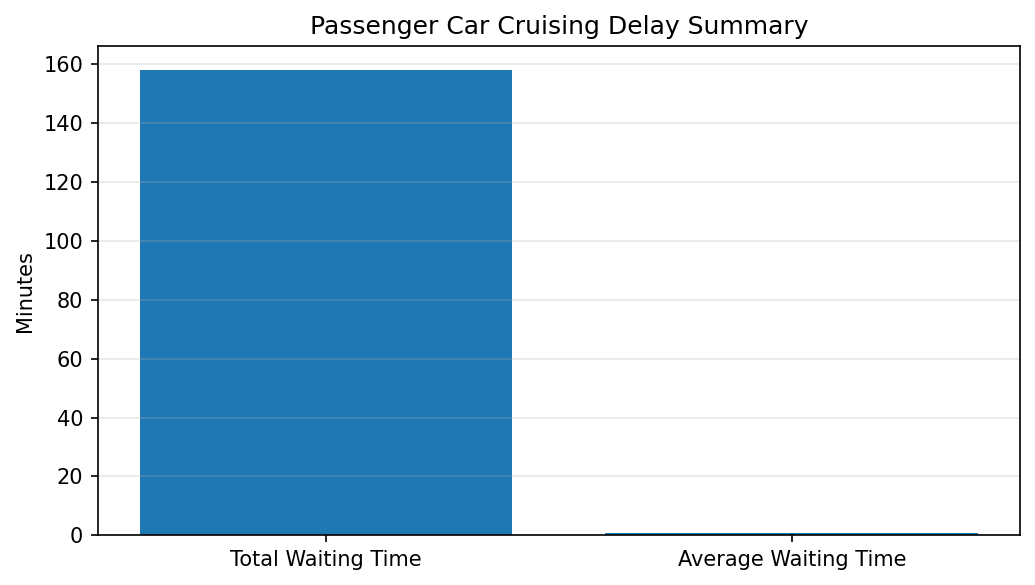

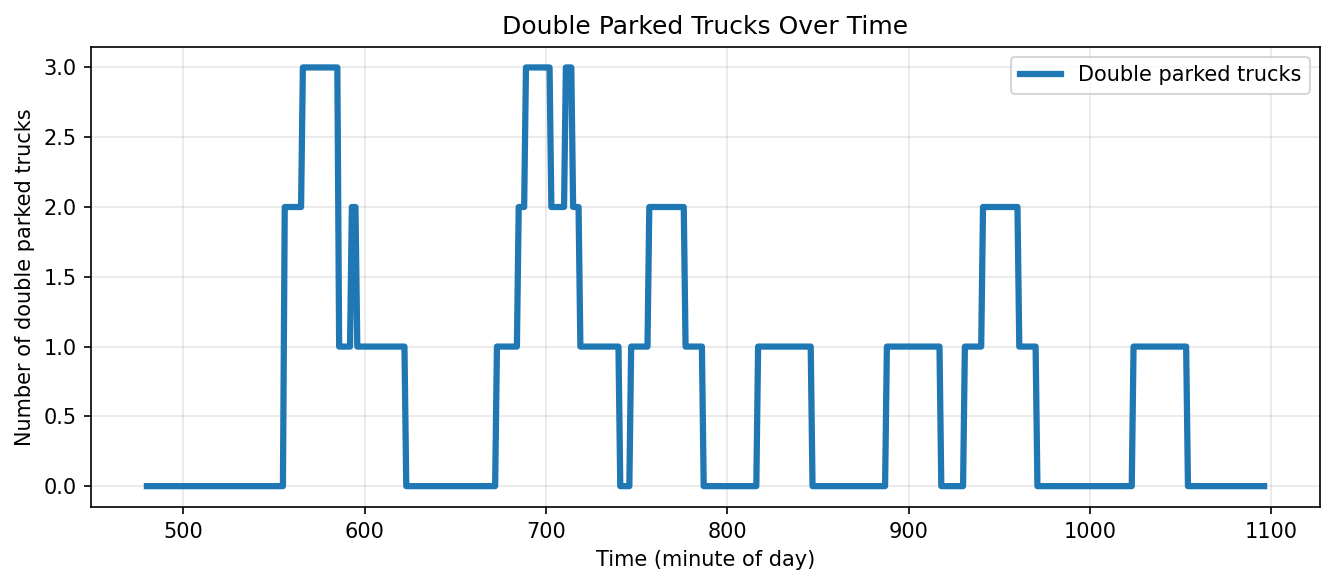

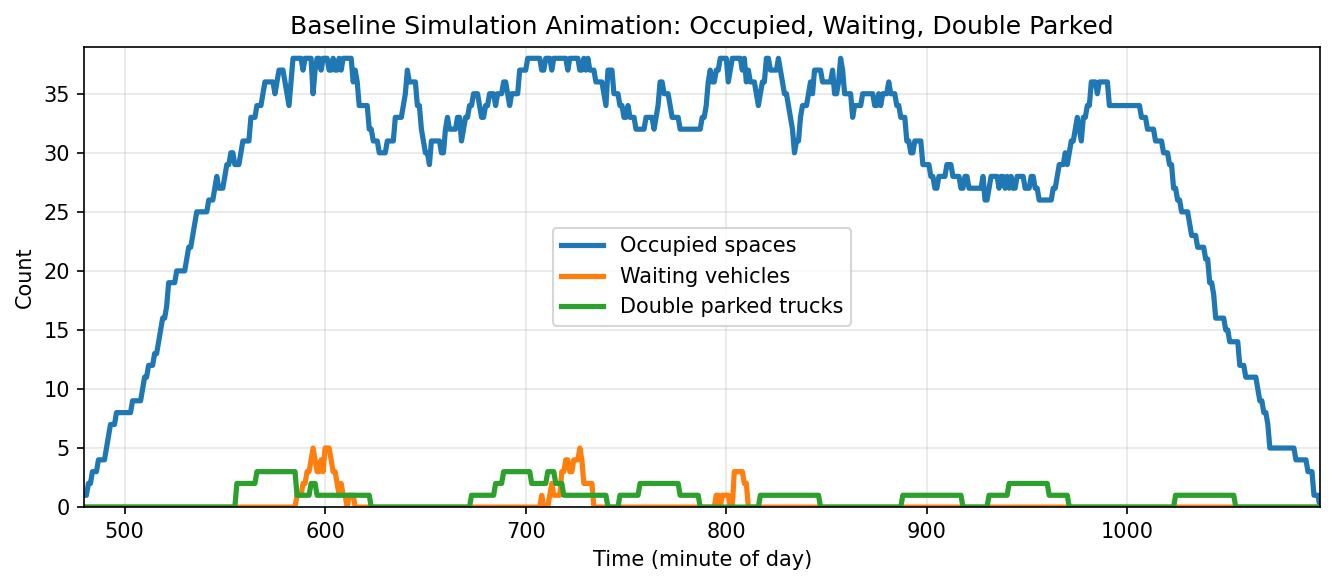

Saved baseline new outputs:
 - results\base_conditions\baseline_plot_08_cruising_delay.pdf
 - results\base_conditions\baseline_plot_09_double_parking.pdf
 - results\base_conditions\baseline_simulation.gif


In [37]:
# New visualization A: cruising delay summary (baseline)
cars_baseline = baseline_data["cars"].copy()
total_waiting_time_minutes = float(cars_baseline["waited_time"].sum())
average_waiting_time_minutes = float(cars_baseline["waited_time"].mean()) if len(cars_baseline) else 0.0

fig, ax = plt.subplots(figsize=(7, 4), dpi=150)
ax.bar(
    ["Total Waiting Time", "Average Waiting Time"],
    [total_waiting_time_minutes, average_waiting_time_minutes],
)
ax.set_title("Passenger Car Cruising Delay Summary")
ax.set_ylabel("Minutes")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
baseline_cruising_pdf = BASELINE_DIR / "baseline_plot_08_cruising_delay.pdf"
fig.savefig(baseline_cruising_pdf, format="pdf", bbox_inches="tight")
plt.show()

# New visualization B: dedicated double parking plot (baseline)
baseline_ts = baseline_data["df_summ"].copy()
fig, ax = plt.subplots(figsize=(9, 4), dpi=150)
ax.plot(
    baseline_ts["t"],
    baseline_ts["num_double_parked"],
    linewidth=3.0,
    label="Double parked trucks",
)
ax.set_title("Double Parked Trucks Over Time")
ax.set_xlabel("Time (minute of day)")
ax.set_ylabel("Number of double parked trucks")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
baseline_double_park_pdf = BASELINE_DIR / "baseline_plot_09_double_parking.pdf"
fig.savefig(baseline_double_park_pdf, format="pdf", bbox_inches="tight")
plt.show()

# New visualization C: optional animation (baseline)
baseline_gif_path = BASELINE_DIR / "baseline_simulation.gif"
try:
    save_system_animation(
        baseline_ts,
        baseline_gif_path,
        "Baseline Simulation Animation: Occupied, Waiting, Double Parked",
    )
except Exception as exc:
    print(f"Could not save baseline GIF animation: {exc}")

print("Saved baseline new outputs:")
print(" -", baseline_cruising_pdf)
print(" -", baseline_double_park_pdf)
print(" -", baseline_gif_path)

## Section 8: enhanced analysis and plots

,Metric,Value
0,Total vehicles,216
1,Total cars,200
2,Total trucks,16
3,Served vehicles (all),216
4,Failed vehicles,0
5,Legally accommodated vehicles,216
6,Vehicles served via double parking,0
7,Served cars,200
8,Failed cars,0
9,Legally accommodated cars,200


,t,num_future,num_arrived,num_parked,num_double_parked,num_departed,num_failed,num_empty,num_occupied,clock,cumulative_arrivals,cumulative_departures,active_in_system,total_spaces,occupancy_ratio
0,480,215,0,1,0,0,0,37,1,08:00,1,0,1,38,0.026316
1,481,215,0,1,0,0,0,37,1,08:01,1,0,1,38,0.026316
2,482,214,0,2,0,0,0,36,2,08:02,2,0,2,38,0.052632
3,483,214,0,2,0,0,0,36,2,08:03,2,0,2,38,0.052632
4,484,213,0,3,0,0,0,35,3,08:04,3,0,3,38,0.078947


,id,type,status,arrive_time,departure_time,assigned_lot_id,waited_time,parked_time,max_wait_time,park_len,was_double_parked,served_flag,failed_flag,double_parked_flag,legally_accommodated_flag,cruised_flag
0,0,car,DEPARTED,480,554,38,0,74,10,74,False,1,0,0,1,0
1,1,car,DEPARTED,482,553,37,0,71,10,71,False,1,0,0,1,0
2,2,car,DEPARTED,484,547,36,0,63,10,63,False,1,0,0,1,0
3,3,car,DEPARTED,487,559,35,0,72,10,72,False,1,0,0,1,0
4,4,car,DEPARTED,491,557,34,0,66,10,66,False,1,0,0,1,0


Total number of congestion intervals: 0
Truck outcomes by status:


,status,count
0,DEPARTED,16


Average truck waiting time: 0.0 min
Maximum truck waiting time: 0 min
Served trucks: 16
Failed trucks: 0
Legally accommodated trucks: 16
Double-parked trucks: 0


,id,status,was_double_parked,double_parked_flag,assigned_lot_id
13,13,DEPARTED,False,0,25
31,31,DEPARTED,False,0,24
32,32,DEPARTED,False,0,25
38,38,DEPARTED,False,0,10
51,51,DEPARTED,False,0,24
86,86,DEPARTED,False,0,24
90,90,DEPARTED,False,0,10
94,94,DEPARTED,False,0,25
103,103,DEPARTED,False,0,24
118,118,DEPARTED,False,0,24


,id,status,waited_time,max_wait_time
0,0,DEPARTED,0,10
1,1,DEPARTED,0,10
2,2,DEPARTED,0,10
3,3,DEPARTED,0,10
4,4,DEPARTED,0,10
5,5,DEPARTED,0,10
6,6,DEPARTED,0,10
7,7,DEPARTED,0,10
8,8,DEPARTED,0,10
9,9,DEPARTED,0,10


Representative car:
Vehicle 0 (car): arrived at 08:00, waited 0 min, service time 74 min, final status = DEPARTED, assigned lot = 38.

Representative truck:
Vehicle 13 (truck): arrived at 08:37, waited 0 min, service time 30 min, final status = DEPARTED, assigned lot = 25.


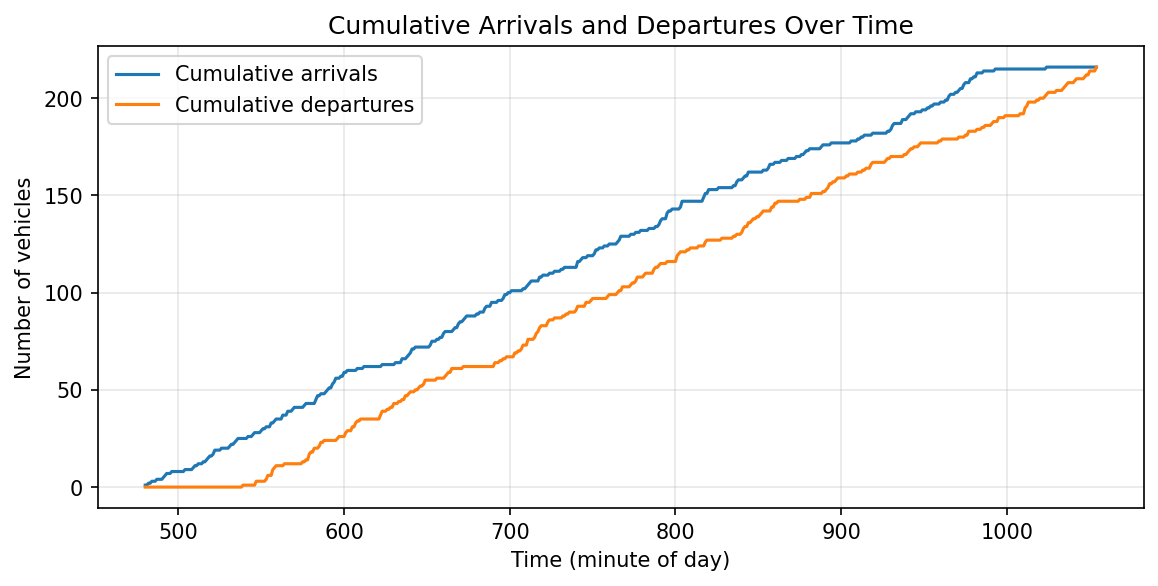

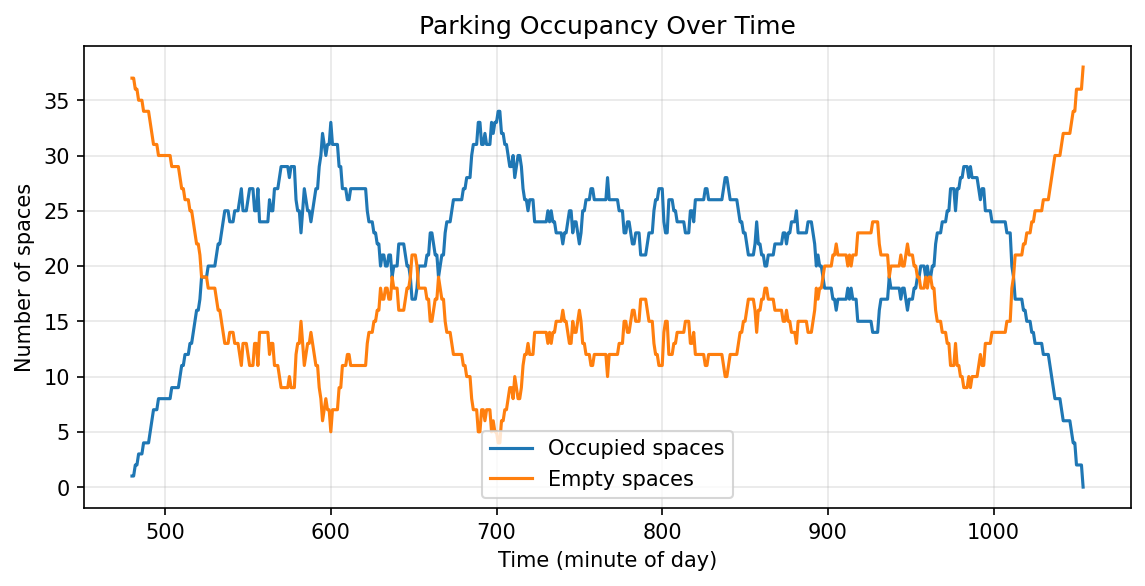

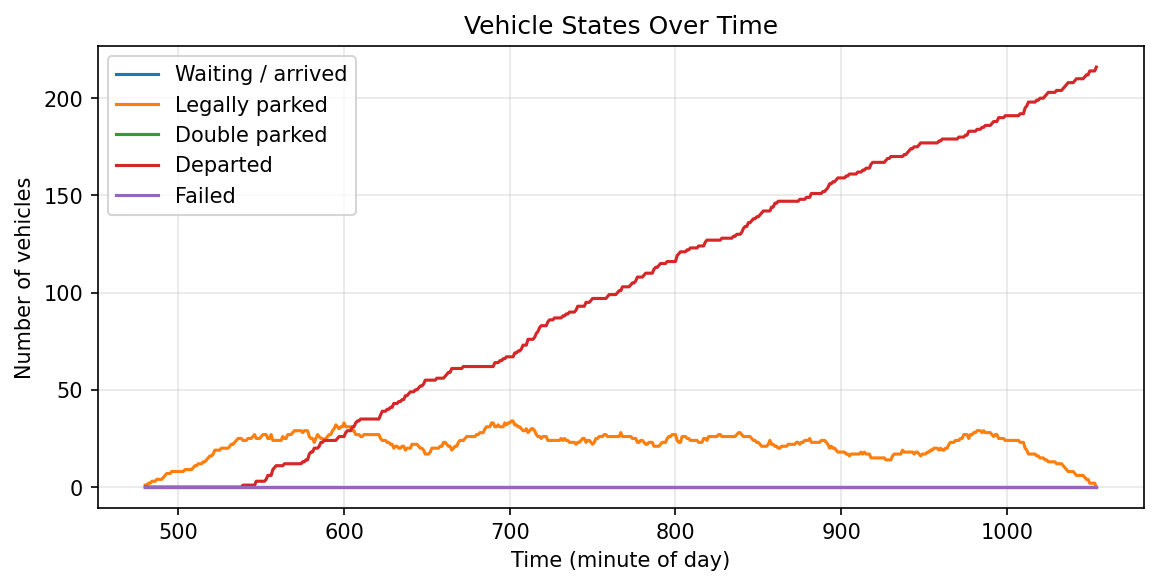

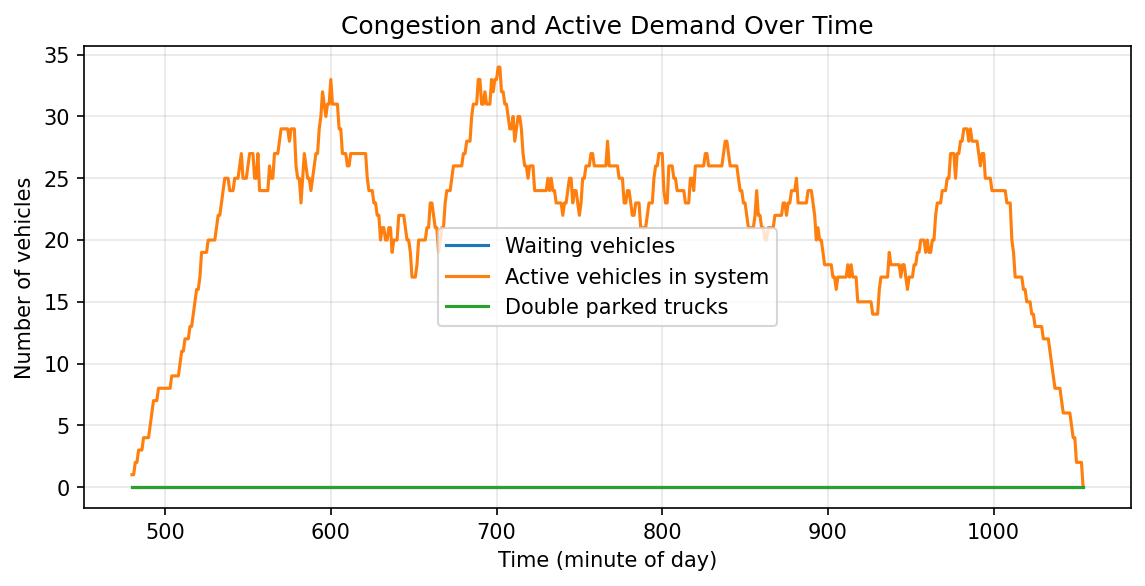

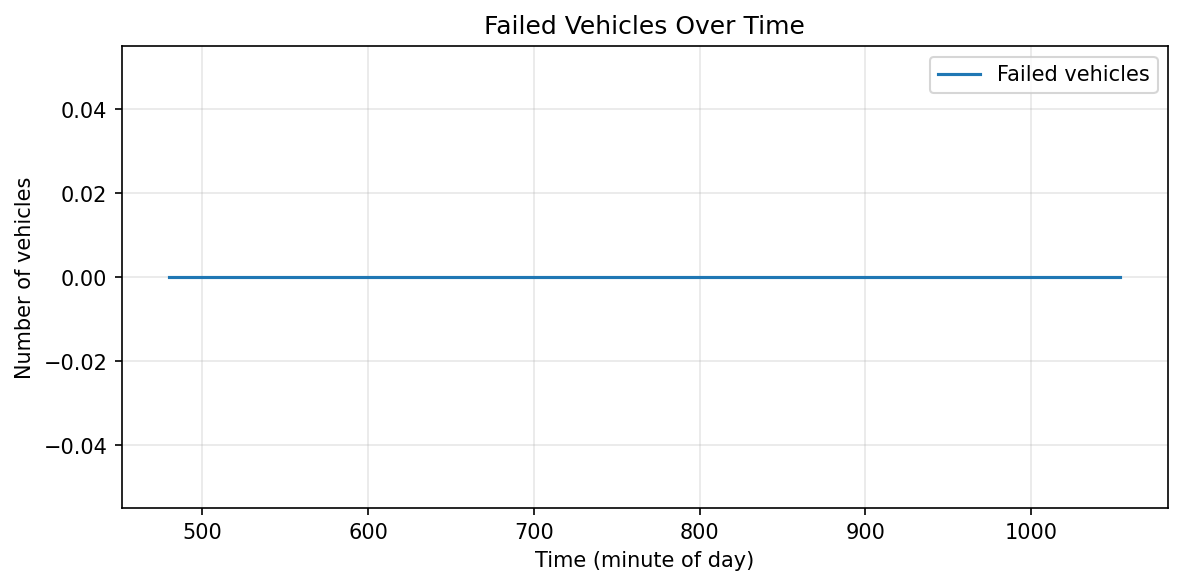

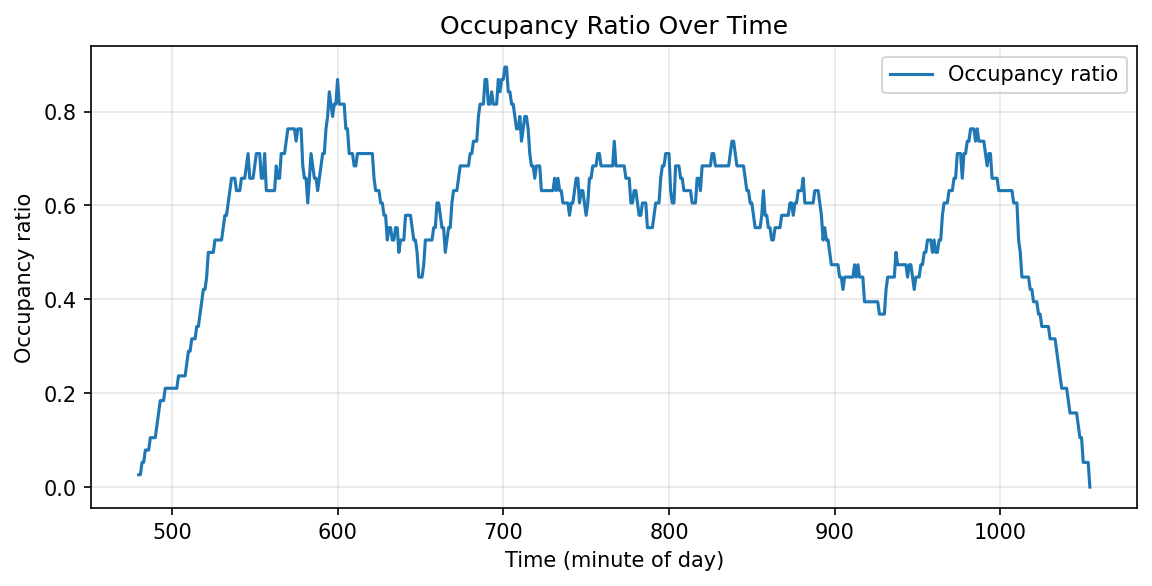

In [38]:
enhanced_data = prepare_scenario_tables(enhanced_time_series, enhanced_results)

display(enhanced_data["metrics_df"])
display(enhanced_data["df_summ"].head())
display(enhanced_data["df_veh"].head())

print("Total number of congestion intervals:", len(enhanced_data["congestion_intervals"]))
if len(enhanced_data["congestion_intervals"]):
    print("\nLongest congestion interval:")
    display(enhanced_data["congestion_intervals"].sort_values("duration_min", ascending=False).head(1))
    display(enhanced_data["congestion_intervals"])

print("Truck outcomes by status:")
display(enhanced_data["truck_status_table"])
print(
    "Average truck waiting time:",
    round(float(enhanced_data["trucks"]["waited_time"].mean()) if len(enhanced_data["trucks"]) else 0.0, 2),
    "min",
)
print(
    "Maximum truck waiting time:",
    int(enhanced_data["trucks"]["waited_time"].max()) if len(enhanced_data["trucks"]) else 0,
    "min",
)

served_trucks_enh = int((enhanced_data["trucks"]["status"] != "FAILED").sum())
failed_trucks_enh = int((enhanced_data["trucks"]["status"] == "FAILED").sum())
legal_trucks_enh = int(enhanced_data["trucks"]["assigned_lot_id"].notna().sum())
double_trucks_enh = int(enhanced_data["trucks"]["was_double_parked"].sum())

print("Served trucks:", served_trucks_enh)
print("Failed trucks:", failed_trucks_enh)
print("Legally accommodated trucks:", legal_trucks_enh)
print("Double-parked trucks:", double_trucks_enh)

display(
    enhanced_data["trucks"][
        ["id", "status", "was_double_parked", "double_parked_flag", "assigned_lot_id"]
    ].head(20)
)
display(
    enhanced_data["cars"][["id", "status", "waited_time", "max_wait_time"]]
    .sort_values("waited_time", ascending=False)
    .head(20)
)

print("Representative car:")
print(enhanced_data["car_story"])
print("\nRepresentative truck:")
print(enhanced_data["truck_story"])

plot_scenario_timeseries(
    enhanced_data,
    prefix="enhanced",
    output_dir=ENHANCED_PLOTS_DIR,
    counter=PLOT_SAVE_COUNTS,
    counter_key="enhanced",
)

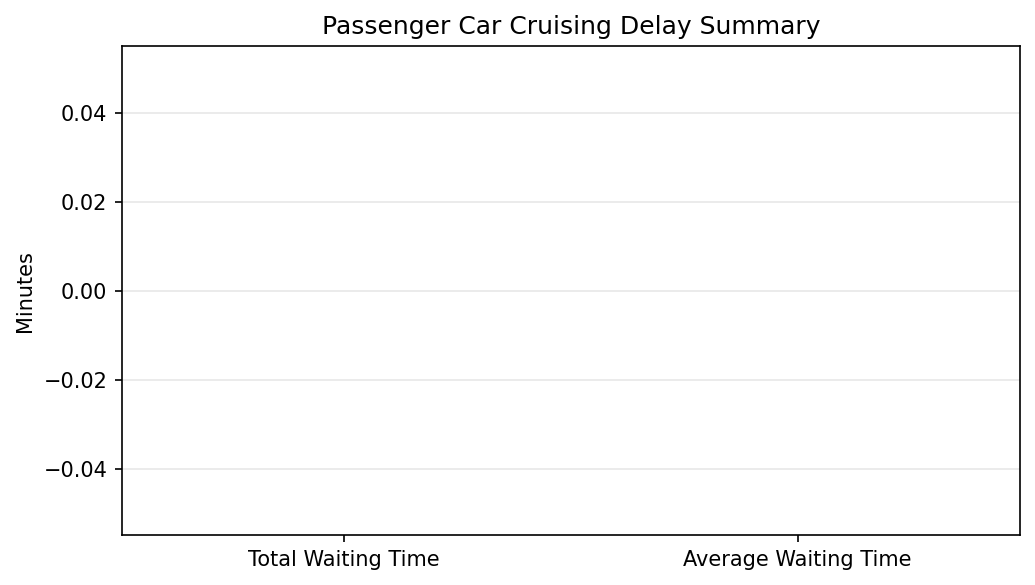

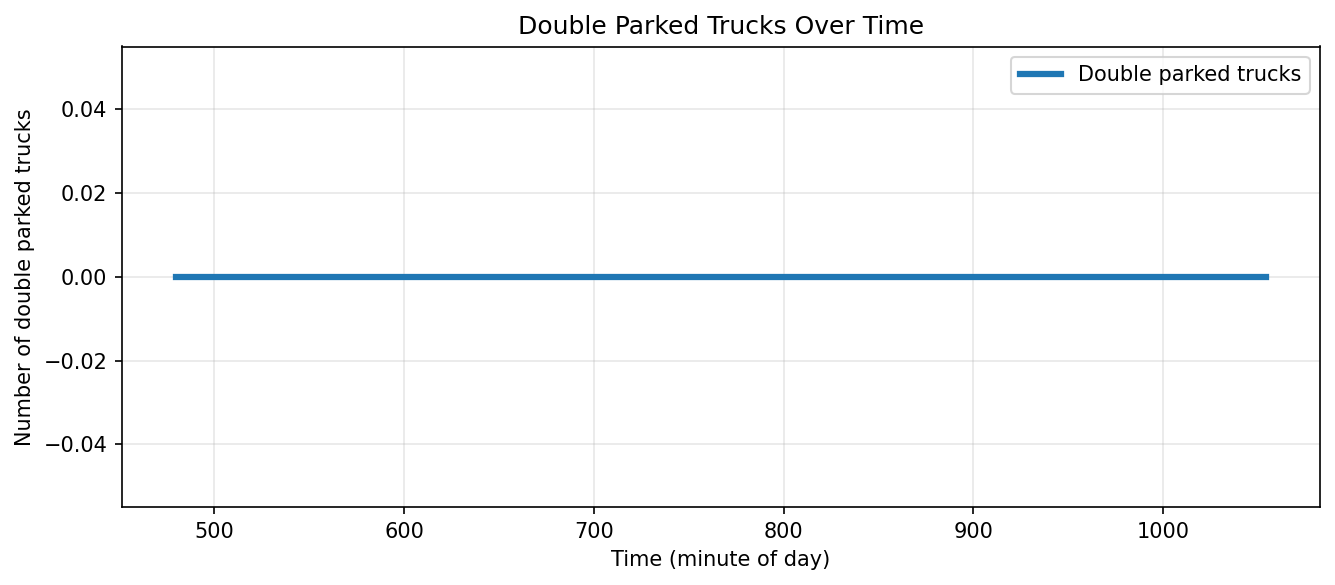

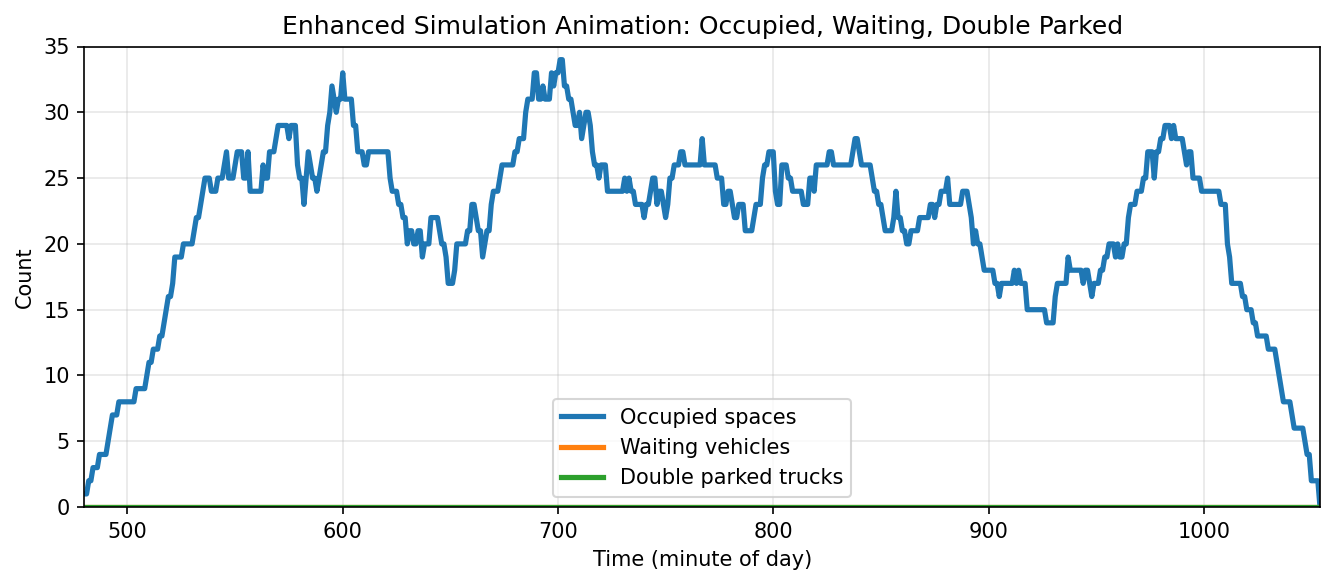

Saved enhanced new outputs:
 - results\enhanced\enhanced_plot_08_cruising_delay.pdf
 - results\enhanced\enhanced_plot_09_double_parking.pdf
 - results\enhanced\enhanced_simulation.gif


In [39]:
# New visualization A: cruising delay summary (enhanced)
cars_enhanced = enhanced_data["cars"].copy()
total_waiting_time_minutes = float(cars_enhanced["waited_time"].sum())
average_waiting_time_minutes = float(cars_enhanced["waited_time"].mean()) if len(cars_enhanced) else 0.0

fig, ax = plt.subplots(figsize=(7, 4), dpi=150)
ax.bar(
    ["Total Waiting Time", "Average Waiting Time"],
    [total_waiting_time_minutes, average_waiting_time_minutes],
)
ax.set_title("Passenger Car Cruising Delay Summary")
ax.set_ylabel("Minutes")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
enhanced_cruising_pdf = ENHANCED_DIR / "enhanced_plot_08_cruising_delay.pdf"
fig.savefig(enhanced_cruising_pdf, format="pdf", bbox_inches="tight")
plt.show()

# New visualization B: dedicated double parking plot (enhanced)
enhanced_ts = enhanced_data["df_summ"].copy()
fig, ax = plt.subplots(figsize=(9, 4), dpi=150)
ax.plot(
    enhanced_ts["t"],
    enhanced_ts["num_double_parked"],
    linewidth=3.0,
    label="Double parked trucks",
)
ax.set_title("Double Parked Trucks Over Time")
ax.set_xlabel("Time (minute of day)")
ax.set_ylabel("Number of double parked trucks")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
enhanced_double_park_pdf = ENHANCED_DIR / "enhanced_plot_09_double_parking.pdf"
fig.savefig(enhanced_double_park_pdf, format="pdf", bbox_inches="tight")
plt.show()

# New visualization C: optional animation (enhanced)
enhanced_gif_path = ENHANCED_DIR / "enhanced_simulation.gif"
try:
    save_system_animation(
        enhanced_ts,
        enhanced_gif_path,
        "Enhanced Simulation Animation: Occupied, Waiting, Double Parked",
    )
except Exception as exc:
    print(f"Could not save enhanced GIF animation: {exc}")

print("Saved enhanced new outputs:")
print(" -", enhanced_cruising_pdf)
print(" -", enhanced_double_park_pdf)
print(" -", enhanced_gif_path)

## Section 9: before-vs-after comparison tables

In [40]:
baseline_row = baseline_summary.iloc[0]
enhanced_row = enhanced_summary.iloc[0]

comparison_df = pd.DataFrame(
    {
        "metric": [
            "total_vehicles",
            "parked_vehicles",
            "double_parked_vehicles",
            "failed_vehicles",
            "departed_vehicles",
            "avg_waited_time_minutes",
        ],
        "baseline": [
            baseline_row["total_vehicles"],
            baseline_row["parked_vehicles"],
            baseline_row["double_parked_vehicles"],
            baseline_row["failed_vehicles"],
            baseline_row["departed_vehicles"],
            baseline_row["avg_waited_time_minutes"],
        ],
        "enhanced": [
            enhanced_row["total_vehicles"],
            enhanced_row["parked_vehicles"],
            enhanced_row["double_parked_vehicles"],
            enhanced_row["failed_vehicles"],
            enhanced_row["departed_vehicles"],
            enhanced_row["avg_waited_time_minutes"],
        ],
    }
)
comparison_df["absolute_change"] = comparison_df["enhanced"] - comparison_df["baseline"]
comparison_df["percent_change_%"] = (
    comparison_df["absolute_change"] / comparison_df["baseline"].replace(0, pd.NA)
) * 100

status_order = ["departed", "parked", "double_parked", "failed", "arrived", "not_arrived"]
baseline_status_counts = baseline_results["final_status"].value_counts().reindex(status_order, fill_value=0)
enhanced_status_counts = enhanced_results["final_status"].value_counts().reindex(status_order, fill_value=0)

status_comparison = pd.DataFrame(
    {
        "baseline": baseline_status_counts,
        "enhanced": enhanced_status_counts,
    }
)
status_comparison["absolute_change"] = status_comparison["enhanced"] - status_comparison["baseline"]

comparison_df.to_csv(COMPARISON_DIR / "comparison_summary.csv", index=False)
status_comparison.reset_index().rename(columns={"index": "final_status"}).to_csv(
    COMPARISON_DIR / "comparison_status_counts.csv", index=False
)

display(comparison_df)
display(status_comparison)

,metric,baseline,enhanced,absolute_change,percent_change_%
0,total_vehicles,216.000,216.0,0.000,0.000000
1,parked_vehicles,197.000,216.0,19.000,9.644670
2,double_parked_vehicles,15.000,0.0,-15.000,-100.000000
3,failed_vehicles,4.000,0.0,-4.000,-100.000000
4,departed_vehicles,212.000,216.0,4.000,1.886792
5,avg_waited_time_minutes,0.731,0.0,-0.731,-100.000000


,baseline,enhanced,absolute_change
final_status,,,
departed,212,216,4
parked,0,0,0
double_parked,0,0,0
failed,4,0,-4
arrived,0,0,0
not_arrived,0,0,0


## Section 10: before-vs-after comparison plots

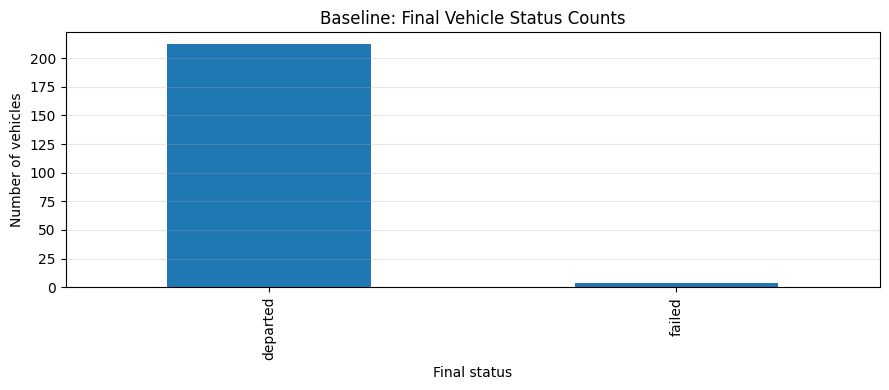

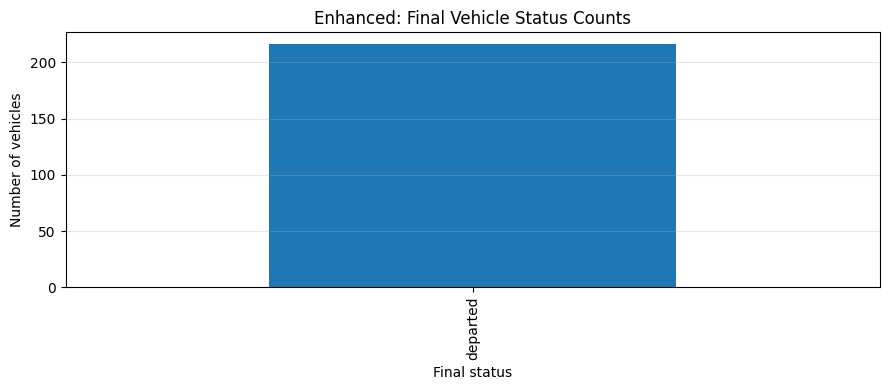

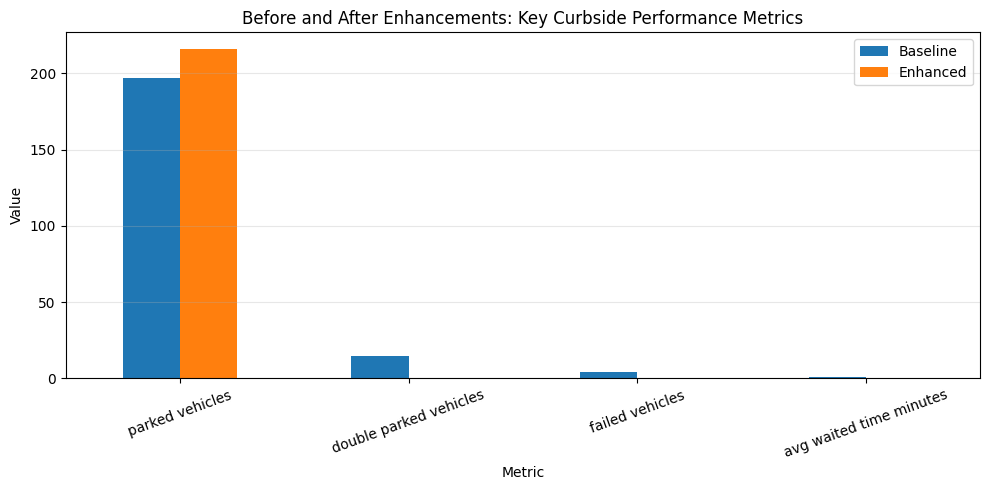

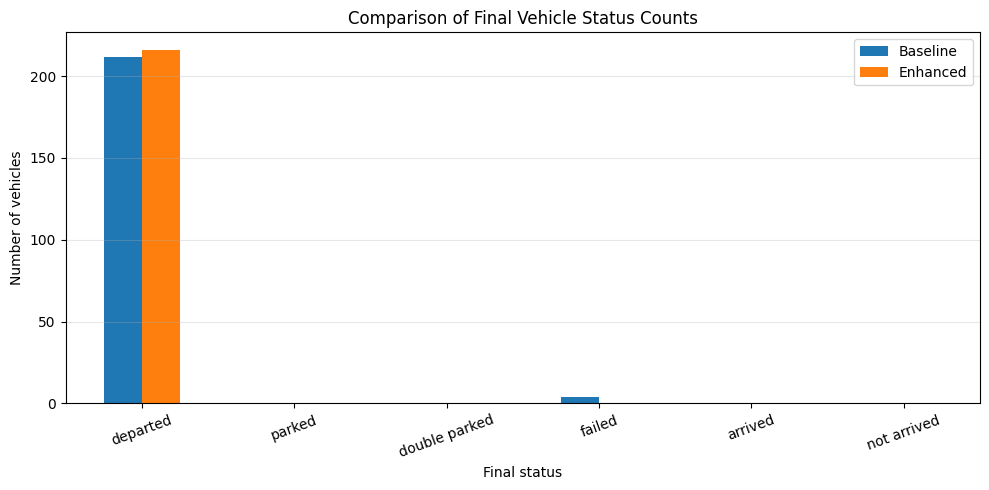

In [41]:
baseline_status_plot = baseline_results["final_status"].value_counts().sort_values(ascending=False)
ax0 = baseline_status_plot.plot(kind="bar", figsize=(9, 4))
ax0.set_title("Baseline: Final Vehicle Status Counts")
ax0.set_xlabel("Final status")
ax0.set_ylabel("Number of vehicles")
ax0.grid(axis="y", alpha=0.3)
plt.tight_layout()
save_current_figure(BASELINE_DIR, "baseline_plot_07_vehicle_status.pdf", PLOT_SAVE_COUNTS, "base_conditions")
plt.show()

enhanced_status_plot = enhanced_results["final_status"].value_counts().sort_values(ascending=False)
axh = enhanced_status_plot.plot(kind="bar", figsize=(9, 4))
axh.set_title("Enhanced: Final Vehicle Status Counts")
axh.set_xlabel("Final status")
axh.set_ylabel("Number of vehicles")
axh.grid(axis="y", alpha=0.3)
plt.tight_layout()
save_current_figure(ENHANCED_DIR, "enhanced_plot_07_vehicle_status.pdf", PLOT_SAVE_COUNTS, "enhanced")
plt.show()

plot_metrics = [
    "parked_vehicles",
    "double_parked_vehicles",
    "failed_vehicles",
    "avg_waited_time_minutes",
]
plot_df = comparison_df.set_index("metric").loc[plot_metrics][["baseline", "enhanced"]]

ax1 = plot_df.plot(kind="bar", figsize=(10, 5))
ax1.set_title("Before and After Enhancements: Key Curbside Performance Metrics")
ax1.set_xlabel("Metric")
ax1.set_ylabel("Value")
ax1.set_xticklabels([m.replace("_", " ") for m in plot_metrics], rotation=20)
ax1.legend(["Baseline", "Enhanced"])
ax1.grid(axis="y", alpha=0.3)
plt.tight_layout()
save_current_figure(COMPARISON_DIR, "comparison_plot_01_summary_metrics.pdf", PLOT_SAVE_COUNTS, "comparison")
plt.gcf().savefig(COMPARISON_DIR / "comparison_main_summary.pdf", format="pdf", bbox_inches="tight")
plt.show()

ax2 = status_comparison[["baseline", "enhanced"]].plot(kind="bar", figsize=(10, 5))
ax2.set_title("Comparison of Final Vehicle Status Counts")
ax2.set_xlabel("Final status")
ax2.set_ylabel("Number of vehicles")
ax2.set_xticklabels([s.replace("_", " ") for s in status_comparison.index], rotation=20)
ax2.legend(["Baseline", "Enhanced"])
ax2.grid(axis="y", alpha=0.3)
plt.tight_layout()
save_current_figure(COMPARISON_DIR, "comparison_plot_02_status_comparison.pdf", PLOT_SAVE_COUNTS, "comparison")
plt.show()

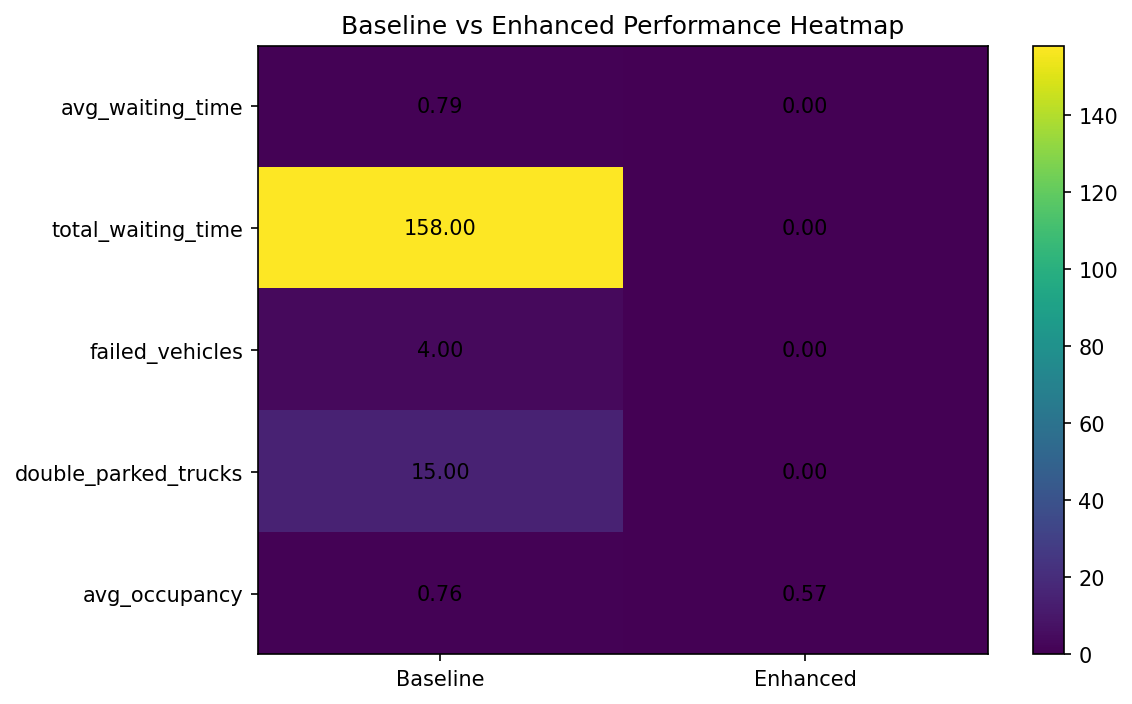

In [42]:
# Comparison heatmap (matplotlib only)
metrics = [
    "avg_waiting_time",
    "total_waiting_time",
    "failed_vehicles",
    "double_parked_trucks",
    "avg_occupancy",
]

baseline_values = [
    float(baseline_data["cars"]["waited_time"].mean()) if len(baseline_data["cars"]) else 0.0,
    float(baseline_data["cars"]["waited_time"].sum()) if len(baseline_data["cars"]) else 0.0,
    float(baseline_summary.iloc[0]["failed_vehicles"]),
    float(baseline_data["trucks"]["was_double_parked"].sum()) if len(baseline_data["trucks"]) else 0.0,
    float(baseline_data["df_summ"]["occupancy_ratio"].mean()),
]

enhanced_values = [
    float(enhanced_data["cars"]["waited_time"].mean()) if len(enhanced_data["cars"]) else 0.0,
    float(enhanced_data["cars"]["waited_time"].sum()) if len(enhanced_data["cars"]) else 0.0,
    float(enhanced_summary.iloc[0]["failed_vehicles"]),
    float(enhanced_data["trucks"]["was_double_parked"].sum()) if len(enhanced_data["trucks"]) else 0.0,
    float(enhanced_data["df_summ"]["occupancy_ratio"].mean()),
]

comparison_df = pd.DataFrame(
    {
        "Baseline": baseline_values,
        "Enhanced": enhanced_values,
    },
    index=metrics,
)

fig, ax = plt.subplots(figsize=(8, 4.8), dpi=150)
cax = ax.imshow(comparison_df.values, aspect="auto")

ax.set_xticks(range(len(comparison_df.columns)))
ax.set_xticklabels(comparison_df.columns)

ax.set_yticks(range(len(comparison_df.index)))
ax.set_yticklabels(comparison_df.index)

fig.colorbar(cax)
ax.set_title("Baseline vs Enhanced Performance Heatmap")

for i in range(comparison_df.shape[0]):
    for j in range(comparison_df.shape[1]):
        ax.text(
            j,
            i,
            f"{comparison_df.values[i, j]:.2f}",
            ha="center",
            va="center",
            color="black",
        )

plt.tight_layout()
plt.savefig(COMPARISON_DIR / "comparison_heatmap.pdf", format="pdf", bbox_inches="tight")
plt.show()

## Section 11: save plots as PDFs

All plots are saved as `.pdf` files and also shown inline in notebook output.

In [43]:
print("Baseline results files:")
print(" -", baseline_results_path)
print(" -", baseline_summary_path)
print(" -", BASELINE_DIR / "baseline_plot_08_cruising_delay.pdf")
print(" -", BASELINE_DIR / "baseline_plot_09_double_parking.pdf")
print(" -", BASELINE_DIR / "baseline_simulation.gif")

print("\nEnhanced results files:")
print(" -", enhanced_results_path)
print(" -", enhanced_summary_path)
print(" -", ENHANCED_DIR / "enhanced_plot_08_cruising_delay.pdf")
print(" -", ENHANCED_DIR / "enhanced_plot_09_double_parking.pdf")
print(" -", ENHANCED_DIR / "enhanced_simulation.gif")

print("\nComparison files:")
print(" -", COMPARISON_DIR / "comparison_summary.csv")
print(" -", COMPARISON_DIR / "comparison_status_counts.csv")
print(" -", COMPARISON_DIR / "comparison_plot_01_summary_metrics.pdf")
print(" -", COMPARISON_DIR / "comparison_plot_02_status_comparison.pdf")
print(" -", COMPARISON_DIR / "comparison_main_summary.pdf")

print("\nPlots saved by folder:")
print(f" - {BASELINE_DIR}: {PLOT_SAVE_COUNTS['base_conditions']}")
print(f" - {ENHANCED_DIR}: {PLOT_SAVE_COUNTS['enhanced']}")
print(f" - {COMPARISON_DIR}: {PLOT_SAVE_COUNTS['comparison']}")

Baseline results files:
 - results\base_conditions\baseline_results.csv
 - results\base_conditions\baseline_summary.csv
 - results\base_conditions\baseline_plot_08_cruising_delay.pdf
 - results\base_conditions\baseline_plot_09_double_parking.pdf
 - results\base_conditions\baseline_simulation.gif

Enhanced results files:
 - results\enhanced\enhanced_results.csv
 - results\enhanced\enhanced_summary.csv
 - results\enhanced\enhanced_plot_08_cruising_delay.pdf
 - results\enhanced\enhanced_plot_09_double_parking.pdf
 - results\enhanced\enhanced_simulation.gif

Comparison files:
 - results\comparison\comparison_summary.csv
 - results\comparison\comparison_status_counts.csv
 - results\comparison\comparison_plot_01_summary_metrics.pdf
 - results\comparison\comparison_plot_02_status_comparison.pdf
 - results\comparison\comparison_main_summary.pdf

Plots saved by folder:
 - results\base_conditions: 7
 - results\enhanced: 7
 - results\comparison: 2


## Section 12: final interpretation / conclusions

This notebook uses the same unified simulator and compares two input scenarios.

Enhancement summary:
- expanded truck loading spaces from 2 to 4
- truck-only loading bays
- reduced car parking duration from 1.0–2.0 h to 0.75–1.25 h
- reduced car waiting time from 15 min to 10 min

Interpretation guidance:
- Lower `double_parked_vehicles` and `failed_vehicles` indicates improved curb operations.
- Higher `parked_vehicles` and `departed_vehicles` indicates improved throughput.
- Lower `avg_waited_time_minutes` indicates less search/cruising delay.